In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar tu paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))


# 05 · Torneo de modelos

**Proyecto RiskVision · Grupo 6.** Dataset: *Default of Credit Card Clients* (UCI, CC BY 4.0).

## Para qué sirve este notebook
Elegir **uno o dos finalistas** para optimizar, con evidencia y sin abrir la prueba. El torneo **descarta, no corona**: la optimización puede cambiar el orden, y el modelo elegido solo se podrá juzgar al final, con datos que no se hayan usado para decidir.

## Reglas del torneo
1. **Mismos datos y mismos pliegues** para todos los modelos (los de la etapa 4).
2. **Mismas variables** para todos: el paquete final de la etapa 4 (`FINAL_FEATURES`). La única excepción es una variante extra de LightGBM con el paquete D, para cerrar un pendiente de esa etapa, y se identifica con claridad.
3. **Tres líneas base** que cualquier modelo serio debe vencer: no hacer nada, marcar a todos y la regla simple del EDA (`PAY_0 ≥ 2`).
4. **Se guarda cada pliegue**, no solo el promedio, para comparar de a pares.
5. **Parámetros fijos y razonables** para todos. Aquí no se optimiza nada; eso es la etapa 6.

## Cuatro advertencias
1. **Métrica que decide: ROC AUC**, como dice la ficha del caso (`reports/00_caso.md`). La penalización relativa 5 a 1 es una **hipótesis del grupo**, no un costo del banco, y se usa como control.
2. **La prueba no se abre.** Además, ya se exploró y se evaluó antes (revisión H1), así que no sirve como evaluación final independiente.
3. **El umbral 1/6 favorece a los modelos bien calibrados.** Es el punto de indiferencia de la matriz 5 a 1 solo si las probabilidades son confiables. Por eso se agrega una medida que no depende de la calibración: cuántos incumplidores se capturan al revisar el 20 % de mayor riesgo.
4. **Los modelos no están afinados.** Una diferencia pequeña entre dos modelos de boosting puede cambiar al optimizarlos.

## Palabras clave
| Término | Significado simple |
|---|---|
| **Línea base** | Un «modelo» sin aprendizaje. Si un modelo serio no lo supera, no sirve |
| **Calibración** | Que una probabilidad del 30 % signifique que de cada 100 clientes así, unos 30 incumplen |
| **Sensibilidad** | Repetir la comparación cambiando un supuesto (el 5 a 1, o cuántos clientes se pueden revisar) para ver si cambia el resultado |
| **Pliegue** | Cada vez que se entrena con una parte de los datos y se mide con otra. Aquí son 15 (5 × 3 repeticiones) |
| **AUC / AUC-PR** | Qué tan bien ordena a los clientes del menos al más riesgoso. El AUC-PR es más exigente con la clase rara; al azar vale 0,22 |
| **Recall de incumple** | De los clientes que sí incumplen, a cuántos detecta el modelo |
| **Recall de paga** | De los clientes que sí pagan, a cuántos deja pasar. Si es muy bajo, el modelo marca a casi todos |
| **Penalización relativa** | Con la hipótesis 5 a 1, el castigo medio por cliente por equivocarse. Menor es mejor. No es dinero |
| **Log loss y Brier** | Qué tan confiables son las probabilidades. Menor es mejor |


## 0. Cargar los datos de entrenamiento
**Qué hace la celda:** lee `data/processed/train.joblib` (lo genera el notebook 03), comprueba que ningún cliente se repite y separa los predictores del objetivo. **No se carga la prueba.**

In [2]:
import joblib
import pandas as pd

from proyecto.config import PROCESSED_DIR, ROOT
from proyecto.data.split import assert_unique_ids, make_xy

train = joblib.load(PROCESSED_DIR / "train.joblib")
assert_unique_ids(train)                      # un cliente por fila: partir por fila es válido
X, y = make_xy(train)
y = y.to_numpy()
print(f"entrenamiento: {X.shape[0]:,} filas x {X.shape[1]} predictores (la prueba NO se abre)")
print(f"tasa de incumplimiento: {y.mean():.2%}")


entrenamiento: 24,000 filas x 23 predictores (la prueba NO se abre)
tasa de incumplimiento: 22.12%


## 1. Validación común
**Qué hace la celda:** arma los **mismos 15 pliegues de la etapa 4** (5 estratificados, repetidos 3 veces, semilla 42) y comprueba que ningún cliente queda en los dos lados de un pliegue. Todos los modelos se miden con estos pliegues.

In [3]:
from proyecto.config import RANDOM_STATE
from proyecto.models.evaluate import repeated_folds

pliegues = repeated_folds(X, y, n_splits=5, n_repeats=3, seed=RANDOM_STATE)
for i_train, i_valid in pliegues:
    assert set(i_train).isdisjoint(i_valid)
    assert abs(y[i_valid].mean() - y.mean()) < 0.005
print(f"{len(pliegues)} pliegues, los mismos para todos los modelos")

15 pliegues, los mismos para todos los modelos


## 2. Variables y métricas
**Qué hace la celda:** fija las variables del torneo (el paquete final de la etapa 4, cinco columnas nuevas sobre las 23 originales) y el paquete D, que solo usa la variante extra. Las métricas las calcula `technical_metrics`, probada con valores hechos a mano:
- **Con probabilidades** (no dependen de decidir): ROC AUC, AUC-PR, log loss, Brier.
- **Con la decisión «marcar si la probabilidad ≥ 1/6»:** exactitud balanceada, F1 macro, precisión y recall por clase, porcentaje marcado y penalización relativa.
- **Con capacidad fija:** recall y *lift* al revisar el 20 % de mayor riesgo. Ese 20 % es un escenario supuesto, no una capacidad medida.

In [4]:
from proyecto.features.build import FINAL_FEATURES

METRICA = "roc_auc"            # la que decide quién avanza (ficha del caso)
print("paquete final de variables:", list(FINAL_FEATURES))

paquete final de variables: ['utilization_mean', 'pending_balance_last', 'delay_streak', 'n_zero_payments', 'log_limit']


## 3. Candidatos
**Qué hace la celda:** define los modelos con **parámetros fijos de partida** y la misma forma de armar su `Pipeline` (`build_pipeline`). Todo lo que se aprende de los datos se ajusta dentro de cada pliegue.

| Candidato | Por qué está |
|---|---|
| Línea base: siempre paga | Es la estrategia trivial del notebook 01: acierta 77,9 % sin detectar a nadie |
| Línea base: prior | Da a todos la misma probabilidad (la tasa de incumplimiento); con el umbral 1/6 equivale a marcar a todos |
| Línea base: regla `PAY_0 ≥ 2` | La regla simple del EDA: marca a quien lleva 2 o más meses de atraso. Si un modelo no la supera con claridad, no justifica su complejidad |
| Regresión logística | El modelo simple y explicable, el contraste |
| Bosque aleatorio | Árboles en paralelo; suele ser robusto |
| LightGBM y XGBoost | Gradient boosting, el candidato principal según el EDA y el notebook 01 |
| LightGBM + paquete D | Variante extra: ¿conviene usar las 10 variables del paquete D en vez de las 5? |
| LightGBM calibrado | Variante extra: el mismo LightGBM con un ajuste que corrige sus probabilidades (calibración isotónica, hecha solo con datos de entrenamiento de cada pliegue) |

Ningún modelo usa pesos de clase: el desbalance se maneja con el umbral y con las métricas, no con el entrenamiento.

In [5]:
from proyecto.models.candidates import tournament_candidates

candidatos = tournament_candidates()      # nombre -> función que arma un modelo nuevo (parámetros en candidates.py)
print(f"{len(candidatos)} candidatos definidos")

9 candidatos definidos


## 4. Correr el torneo
**Qué hace la celda:** para cada candidato ajusta un `Pipeline` nuevo en cada uno de los 15 pliegues y guarda **una fila por pliegue** con todas las métricas y los segundos de ajuste, además de las predicciones de validación para revisar la calibración. El resultado completo se guarda en `reports/05_torneo_por_pliegue.csv` para poder revisarlo después. Tarda varios minutos.

In [6]:
from proyecto.models.evaluate import score_folds_detailed

por_pliegue, predicciones = {}, {}
for nombre, fabrica in candidatos.items():
    por_pliegue[nombre], predicciones[nombre] = score_folds_detailed(fabrica, X, y, pliegues, keep_predictions=True)
    print(f"{nombre:28s} listo ({por_pliegue[nombre]['fit_seconds'].sum():.0f} s en total)")

completo = pd.concat({n: f.rename_axis("pliegue") for n, f in por_pliegue.items()}, names=["modelo"]).reset_index()
completo.to_csv(ROOT / "reports" / "05_torneo_por_pliegue.csv", index=False, float_format="%.6f")
print("guardado: reports/05_torneo_por_pliegue.csv", completo.shape)


línea base: siempre paga     listo (0 s en total)


línea base: prior            listo (1 s en total)
línea base: regla PAY_0 ≥ 2  listo (0 s en total)


regresión logística          listo (2 s en total)


bosque aleatorio             listo (26 s en total)


LightGBM                     listo (4 s en total)


XGBoost                      listo (7 s en total)


LightGBM + paquete D         listo (4 s en total)


LightGBM calibrado           listo (10 s en total)
guardado: reports/05_torneo_por_pliegue.csv (135, 21)


## 5. Tabla resumen y variabilidad
**Qué hace la celda:** ordena los modelos por ROC AUC medio e indica cuánto varía entre pliegues (± desviación) y cuánto tardó el ajuste. El gráfico muestra los 15 valores de cada modelo: si dos cajas se solapan mucho, la diferencia puede ser ruido.

,ROC AUC (media),± entre pliegues,segundos por ajuste
LightGBM + paquete D,0.7885,0.0060,0.2591
LightGBM calibrado,0.7877,0.0064,0.6803
XGBoost,0.7872,0.0063,0.4442
LightGBM,0.7870,0.0063,0.2613
bosque aleatorio,0.7868,0.0057,1.7194
regresión logística,0.7785,0.0059,0.1631
línea base: regla PAY_0 ≥ 2,0.6435,0.0058,0.0019
línea base: siempre paga,0.5000,0.0000,0.0330
línea base: prior,0.5000,0.0000,0.0410


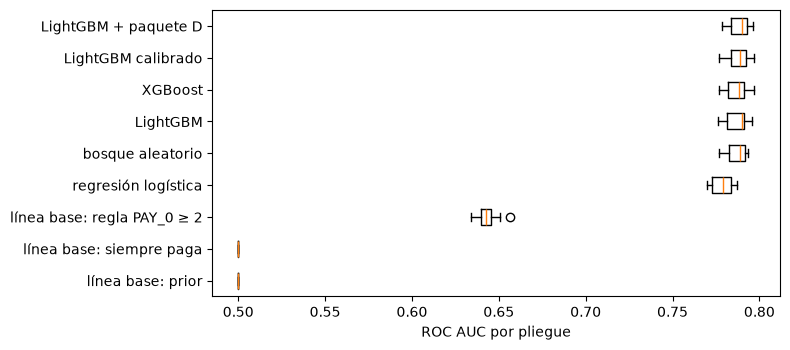

In [7]:
import matplotlib.pyplot as plt

from proyecto.models.tournament import summarize_by_model

resumen = summarize_by_model(por_pliegue, METRICA)
display(resumen.round(4))

orden = list(resumen.index)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.boxplot([por_pliegue[n][METRICA] for n in orden], vert=False, tick_labels=orden, widths=0.5)
ax.invert_yaxis()
ax.set_xlabel("ROC AUC por pliegue")
plt.tight_layout()
plt.show()

### 5.1 Métricas técnicas
**Qué hace la celda:** muestra la media de las métricas técnicas de cada modelo. Fíjese sobre todo en el **recall de cada clase**: un modelo que marca a casi todos tiene recall de «incumple» altísimo pero deja pasar a muy pocos clientes que sí pagan.

In [8]:
from proyecto.models.tournament import technical_table

tecnicas = technical_table(por_pliegue, order=resumen.index)
print(f"tasa real de incumplimiento: {y.mean():.3f} (la «prob. media predicha» debería parecerse)")
display(tecnicas.round(3))

tasa real de incumplimiento: 0.221 (la «prob. media predicha» debería parecerse)


,AUC,AUC-PR,exactitud balanceada,F1 macro,precisión (incumple),recall (paga),recall (incumple),% marcado,penalización 2:1,penalización 5:1,penalización 10:1,log loss,Brier,prob. media predicha,recall al revisar 5 %,recall al revisar 10 %,recall al revisar 20 %,lift al revisar 20 %
LightGBM + paquete D,0.789,0.563,0.704,0.633,0.382,0.654,0.755,0.437,0.299,0.541,0.686,0.424,0.133,0.221,0.172,0.319,0.516,2.582
LightGBM calibrado,0.788,0.562,0.702,0.628,0.378,0.644,0.759,0.445,0.299,0.543,0.692,0.426,0.133,0.221,0.171,0.320,0.517,2.585
XGBoost,0.787,0.564,0.701,0.631,0.380,0.654,0.747,0.434,0.299,0.549,0.690,0.424,0.133,0.221,0.172,0.320,0.518,2.592
LightGBM,0.787,0.563,0.702,0.633,0.382,0.656,0.749,0.434,0.300,0.546,0.691,0.425,0.133,0.221,0.171,0.319,0.516,2.581
bosque aleatorio,0.787,0.559,0.696,0.616,0.366,0.619,0.772,0.467,0.300,0.548,0.686,0.426,0.134,0.222,0.170,0.319,0.516,2.582
regresión logística,0.779,0.548,0.705,0.648,0.400,0.695,0.714,0.395,0.304,0.554,0.714,0.431,0.135,0.221,0.170,0.317,0.510,2.549
línea base: regla PAY_0 ≥ 2,0.643,0.377,0.643,0.669,0.697,0.960,0.327,0.104,0.329,0.775,1.519,NaN,NaN,NaN,0.158,0.315,0.400,1.998
línea base: siempre paga,0.500,0.221,0.500,0.438,0.000,1.000,0.000,0.000,0.442,1.106,2.212,NaN,NaN,NaN,0.050,0.100,0.200,1.000
línea base: prior,0.500,0.221,0.500,0.181,0.221,0.000,1.000,1.000,0.442,0.779,0.779,0.528,0.172,0.221,0.050,0.100,0.200,1.000


### 5.2 ¿Coinciden los rankings?
**Qué hace la celda:** pone la posición de cada modelo (1 = mejor) según varias métricas. Si el mejor por AUC no es el mejor por penalización o por recall, la diferencia viene de **cómo deciden**, no de cómo ordenan.

In [9]:
from proyecto.models.tournament import rank_positions

posiciones = rank_positions(tecnicas, ["AUC", "AUC-PR", "recall al revisar 20 %", "penalización 5:1", "log loss",
                                       "F1 macro", "recall (incumple)"])
display(posiciones)

,AUC,AUC-PR,recall al revisar 20 %,penalización 5:1,log loss,F1 macro,recall (incumple)
LightGBM + paquete D,1,3,3,1,1,3,4
LightGBM calibrado,2,4,2,2,5,6,3
XGBoost,3,1,1,5,2,5,6
LightGBM,4,2,5,3,3,4,5
bosque aleatorio,5,5,4,4,4,7,2
regresión logística,6,6,6,6,6,2,7
línea base: regla PAY_0 ≥ 2,7,7,7,7,<NA>,1,8
línea base: siempre paga,8,8,8,9,<NA>,8,9
línea base: prior,8,8,8,8,7,9,1


### 5.3 Sensibilidad: ¿cambia el resultado si cambian los supuestos?
**Qué hace la celda:** repite la comparación cambiando los dos supuestos más débiles. Primero, **cuánto pesa no detectar a quien incumple**: 2 a 1, 5 a 1 (el supuesto actual) y 10 a 1, cada uno con su umbral teórico (1/3, 1/6 y 1/11). Segundo, **cuántos clientes se pueden revisar**: el 5 %, el 10 % o el 20 % de mayor riesgo. Si el mejor modelo cambia de un escenario a otro, la elección depende del supuesto.

In [10]:
from proyecto.models.tournament import best_by_scenario, is_baseline

penalizaciones = tecnicas[["penalización 2:1", "penalización 5:1", "penalización 10:1"]]
capacidad = tecnicas[["recall al revisar 5 %", "recall al revisar 10 %", "recall al revisar 20 %"]]
print("Penalización relativa por cliente (menor es mejor):")
display(penalizaciones.round(3))
print("\nQué fracción de los incumplidores se captura al revisar solo a los de mayor riesgo (mayor es mejor):")
display(capacidad.round(3))

reales = [n for n in tecnicas.index if not is_baseline(n)]
print("\nMejor modelo (sin contar líneas base) en cada escenario:")
for columna, (nombre, valor) in best_by_scenario(tecnicas, [*penalizaciones.columns, *capacidad.columns], reales).items():
    print(f"  {columna}: {nombre} ({valor:.3f})")

Penalización relativa por cliente (menor es mejor):


,penalización 2:1,penalización 5:1,penalización 10:1
LightGBM + paquete D,0.299,0.541,0.686
LightGBM calibrado,0.299,0.543,0.692
XGBoost,0.299,0.549,0.690
LightGBM,0.300,0.546,0.691
bosque aleatorio,0.300,0.548,0.686
regresión logística,0.304,0.554,0.714
línea base: regla PAY_0 ≥ 2,0.329,0.775,1.519
línea base: siempre paga,0.442,1.106,2.212
línea base: prior,0.442,0.779,0.779



Qué fracción de los incumplidores se captura al revisar solo a los de mayor riesgo (mayor es mejor):


,recall al revisar 5 %,recall al revisar 10 %,recall al revisar 20 %
LightGBM + paquete D,0.172,0.319,0.516
LightGBM calibrado,0.171,0.320,0.517
XGBoost,0.172,0.320,0.518
LightGBM,0.171,0.319,0.516
bosque aleatorio,0.170,0.319,0.516
regresión logística,0.170,0.317,0.510
línea base: regla PAY_0 ≥ 2,0.158,0.315,0.400
línea base: siempre paga,0.050,0.100,0.200
línea base: prior,0.050,0.100,0.200



Mejor modelo (sin contar líneas base) en cada escenario:
  penalización 2:1: LightGBM calibrado (0.299)
  penalización 5:1: LightGBM + paquete D (0.541)
  penalización 10:1: LightGBM + paquete D (0.686)
  recall al revisar 5 %: XGBoost (0.172)
  recall al revisar 10 %: LightGBM calibrado (0.320)
  recall al revisar 20 %: XGBoost (0.518)


### 5.4 Calibración por tramos
**Por qué importa:** el umbral 1/6 solo tiene sentido si una probabilidad del 17 % significa que, de cada 100 clientes así, unos 17 incumplen. Antes solo sabíamos que el promedio coincidía con la tasa real. Aquí se agrupan las predicciones en 10 tramos según su probabilidad (clientes con la misma probabilidad quedan siempre juntos) y se compara lo predicho con lo que pasó realmente. Se usan las predicciones de los 15 pliegues juntas, así que cada cliente aparece 3 veces (una por repetición) y esas copias no son independientes.

**Qué hace la celda:** muestra el **error de calibración** de cada modelo (diferencia media entre lo predicho y lo observado, menor es mejor), qué ocurre justo **alrededor del umbral** (clientes con probabilidad entre 12 % y 22 %) y la tabla por tramos de los modelos principales.

In [11]:
from proyecto.models.tournament import calibration_by_bin, calibration_summary

calibracion = calibration_summary(predicciones, reales)
display(calibracion.round(4))

for nombre in ["LightGBM", "LightGBM calibrado", "regresión logística"]:
    print(f"\nPor tramos de riesgo: {nombre}")
    display(calibration_by_bin(predicciones, nombre).round(3).T)

,error de calibración,predicciones cerca del umbral,prob. predicha ahí,tasa observada ahí
modelo,,,,
LightGBM + paquete D,0.0041,21035,0.1626,0.1620
LightGBM calibrado,0.0038,23896,0.1646,0.1640
XGBoost,0.0053,22866,0.1624,0.1615
LightGBM,0.0038,21800,0.1623,0.1608
bosque aleatorio,0.0092,24361,0.1639,0.1576
regresión logística,0.0101,23558,0.1567,0.1694



Por tramos de riesgo: LightGBM


,0,1,2,3,4,5,6,7,8,9
predicciones,7200.000,7200.000,7200.000,7200.000,7200.000,7200.000,7200.000,7200.000,7200.000,7200.000
prob. predicha,0.038,0.063,0.087,0.110,0.136,0.162,0.199,0.271,0.436,0.706
tasa observada,0.038,0.066,0.089,0.112,0.140,0.167,0.183,0.275,0.436,0.705



Por tramos de riesgo: LightGBM calibrado


,0,1,2,3,4,5,6,7,8,9
predicciones,7200.000,7206.000,7196.000,7198.000,7199.000,7201.000,7204.000,7195.000,7200.000,7201.000
prob. predicha,0.036,0.070,0.091,0.114,0.140,0.166,0.194,0.262,0.436,0.702
tasa observada,0.038,0.068,0.087,0.106,0.145,0.165,0.190,0.270,0.437,0.707



Por tramos de riesgo: regresión logística


,0,1,2,3,4,5,6,7,8,9
predicciones,7200.000,7200.000,7200.000,7200.000,7200.000,7200.000,7200.000,7200.000,7200.000,7200.000
prob. predicha,0.057,0.085,0.100,0.115,0.130,0.151,0.185,0.254,0.420,0.715
tasa observada,0.059,0.060,0.088,0.117,0.135,0.166,0.204,0.255,0.426,0.702


**Qué dicen las métricas técnicas**

- **Los modelos de árboles ordenan casi igual.** Su AUC va de 0,7868 a 0,7885 (diferencia de 0,0017 frente a una variación entre pliegues de ±0,006). La regresión logística queda atrás, con 0,7785.
- **Todos superan con claridad a la regla simple `PAY_0 ≥ 2`.** La regla tiene AUC 0,643 y penalización 0,775, casi igual que marcar a todos (0,779). Los modelos bajan a 0,54–0,55 y, al revisar el 20 % de mayor riesgo, capturan 51–52 % de los incumplidores frente a 40 % de la regla.
- **Pero en los primeros tramos la regla casi no pierde.** Al revisar solo el 5 % o el 10 % de mayor riesgo, la regla captura 15,8 % y 31,5 %; los modelos, 17,0–17,2 % y 31,7–32,0 %. El valor del modelo está sobre todo en ordenar bien al resto de los clientes, no en detectar a los más evidentes.
- **El ranking cambia según la métrica, por muy poco.** Entre los modelos, por AUC lidera LightGBM con el paquete D; por AUC-PR y por recall al revisar el 20 %, XGBoost; por F1 macro, la logística. Es un empate práctico.
- **La sensibilidad al 5 a 1 casi no cambia al líder de los árboles,** pero sí castiga a la logística: su diferencia con el mejor es de 0,005 con 2 a 1, 0,013 con 5 a 1 y 0,028 con 10 a 1. Cuanto más caro es no detectar a quien incumple, más pierde el modelo simple.
- **Calibración.** LightGBM está entre los mejor calibrados (error de calibración 0,0038, empatado con su versión calibrada; las diferencias con la variante D y XGBoost no se distinguen del ruido) y, en la zona del umbral (probabilidad entre 12 % y 22 %), predice 16,2 % y se observa 16,1 %. Eso no contradice usar 1/6 con este modelo, aunque dentro de esa zona hay tramos que se compensan. La logística subestima el riesgo ahí (15,7 % predicho frente a 16,9 % observado, con un error de calibración de 0,010) y el bosque lo sobrestima (16,4 % frente a 15,8 %). Calibrar LightGBM con regresión isotónica no mejora nada: mismo error de calibración, tres veces más lento. La versión calibrada promedia 3 modelos, así que su diferencia mezcla calibrar y promediar.
- **Cómo deciden con el umbral 1/6.** Los árboles marcan entre 43 % y 47 % de los clientes y detectan entre 75 % y 77 % de los que incumplen. La logística marca 39,5 % y detecta 71 %, con mejor precisión (0,40). El bosque es el que más clientes marca (46,7 %) y el que deja pasar a menos de los que sí pagan (recall de «paga» 0,62).
- **Ningún modelo sacrifica una clase.** El recall de «paga» va de 0,62 a 0,70 y el de «incumple», de 0,71 a 0,77.

## 6. Comparación pareada
**Qué hace la celda:** como todos usaron los mismos pliegues, compara de a pares los modelos que importan para la decisión (siempre aparece primero el de mayor AUC medio): ¿gana siempre el mismo? Muestra la diferencia media, en cuántos de los 15 pliegues gana y la **diferencia pareada** (diferencia media ÷ cuánto varía esa diferencia de un pliegue a otro; mayor que 1 es consistente).

In [12]:
from proyecto.models.comparison import pairwise_table

modelos_reales = [n for n in resumen.index if not is_baseline(n)]
PARES = [("LightGBM + paquete D", "LightGBM"), ("LightGBM + paquete D", "XGBoost"), ("LightGBM", "XGBoost"),
         ("LightGBM", "bosque aleatorio"), ("LightGBM calibrado", "LightGBM"), ("LightGBM", "regresión logística")]
display(pairwise_table(por_pliegue, PARES, METRICA).round(4))

,mejor,contra,diferencia media de AUC,pliegues que gana,diferencia pareada
0,LightGBM + paquete D,LightGBM,0.0015,14 de 15,1.2619
1,LightGBM + paquete D,XGBoost,0.0013,11 de 15,0.7731
2,XGBoost,LightGBM,0.0002,8 de 15,0.1548
3,LightGBM,bosque aleatorio,0.0001,8 de 15,0.0662
4,LightGBM calibrado,LightGBM,0.0007,10 de 15,0.6201
5,LightGBM,regresión logística,0.0084,15 de 15,3.4543


### 6.1 Dos preguntas que dejan los resultados
1. **¿Paquete D o paquete E en LightGBM?** La ventaja de D salió en los mismos pliegues con los que se eligió D, así que no es evidencia independiente. Aquí se repite la comparación con pliegues nuevos (semillas 7 y 99).
2. **¿Cuánto pierde la regresión logística frente al mejor boosting?** Se mide con la misma diferencia pareada, para saber si vale la pena como contraste explicable.

In [13]:
from proyecto.models.comparison import compare_pair_on_new_folds
from proyecto.models.evaluate import improvement_over_noise

print("LightGBM con paquete D frente a LightGBM con paquete E, en pliegues nuevos:")
nuevos = compare_pair_on_new_folds(X, y, candidatos["LightGBM"], candidatos["LightGBM + paquete D"], seeds=(7, 99), metric=METRICA)
for semilla, r in nuevos.items():
    print(f"  semilla {semilla}: D - E = {r['gain']:+.4f} de AUC, gana en {r['folds_improved']} de {r['n_folds']}, diferencia pareada {r['paired_gain']:.2f}")

mejor_modelo = modelos_reales[0]
r = improvement_over_noise(reference=por_pliegue["regresión logística"][METRICA], variant=por_pliegue[mejor_modelo][METRICA])
print(f"\n{mejor_modelo} frente a la regresión logística: +{r['gain']:.4f} de AUC, gana en {r['folds_improved']} de {r['n_folds']}, diferencia pareada {r['paired_gain']:.2f}")

LightGBM con paquete D frente a LightGBM con paquete E, en pliegues nuevos:


  semilla 7: D - E = +0.0013 de AUC, gana en 12 de 15, diferencia pareada 0.78
  semilla 99: D - E = +0.0012 de AUC, gana en 12 de 15, diferencia pareada 0.74

LightGBM + paquete D frente a la regresión logística: +0.0100 de AUC, gana en 15 de 15, diferencia pareada 4.79


## 7. ¿Cuánto vale la diferencia?
**Qué hace la celda:** traduce las métricas a volumen **por cada 1.000 clientes**, con el umbral 1/6 y con la tasa de incumplimiento de los datos. No se estima un volumen mensual porque el grupo no tiene un dato de cuántas decisiones toma el banco; inventarlo sería peor que no ponerlo. Las cifras son penalizaciones y conteos bajo la hipótesis 5 a 1, no dinero.

In [14]:
from proyecto.models.tournament import volume_per_thousand

POR = 1000
incumplen = y.mean() * POR
print(f"por cada {POR:,} clientes hay unos {incumplen:.0f} que incumplen")
display(volume_per_thousand(tecnicas, y.mean(), POR).round(0).astype(int))

por cada 1,000 clientes hay unos 221 que incumplen


,se marcan para revisar,incumplidores detectados,incumplidores que se escapan,falsas alarmas,penalización total (5:1),detectados si se revisa el 20 %
LightGBM + paquete D,437,167,54,270,541,114
LightGBM calibrado,445,168,53,277,543,114
XGBoost,434,165,56,269,549,115
LightGBM,434,166,56,268,546,114
bosque aleatorio,467,171,50,296,548,114
regresión logística,395,158,63,237,554,113
línea base: regla PAY_0 ≥ 2,104,72,149,32,775,88
línea base: siempre paga,0,0,221,0,1106,44
línea base: prior,1000,221,0,779,779,44


## 8. Finalistas

**Cómo se eligió.** Se aplicó la regla de la especificación: primero la consistencia entre pliegues, después el AUC, luego que las métricas de control no contradigan, y ante un empate, el tiempo de ajuste y la simplicidad. Hay un empate práctico en el AUC (0,7868 a 0,7885 entre los cuatro modelos de árboles) y ninguna pareja se separa de forma consistente: XGBoost le gana a LightGBM en 8 de 15 pliegues (diferencia pareada 0,15) y LightGBM al bosque, en 8 de 15 (0,07). Por eso el AUC no decide y se pasa a los criterios siguientes.

**Quién ganó.** Gana **LightGBM con el paquete E** por desempate, no por tener el AUC más alto: está entre los mejor calibrados (error 0,0038; en la zona del umbral predice 16,2 % y se observa 16,1 %), ajusta en 0,26 s frente a 0,44 s de XGBoost, 0,68 s de la versión calibrada y 1,7 s del bosque, y usa solo 5 variables nuevas. Su ventaja sobre sus rivales es de simplicidad y confiabilidad de las probabilidades, no de precisión.

| Finalista | Por qué | Qué podría cambiar con la optimización |
|---|---|---|
| **LightGBM con el paquete E** (5 variables) | Empata en AUC con XGBoost, el bosque y la variante D, pero es el más rápido, está bien calibrado en la zona del umbral y su penalización 5:1 (0,546) es de las mejores. Supera con claridad a la regla simple: AUC 0,787 frente a 0,643 y 51,6 % de incumplidores capturados al revisar el 20 %, frente a 40,0 % | XGBoost o el bosque podrían igualarlo o pasarlo al afinar parámetros. El umbral operativo se decide en la etapa 6 con validación |
| **Regresión logística con el paquete E** | Es el contraste explicable. LightGBM le gana en 15 de 15 pliegues (+0,008 de AUC, diferencia pareada 3,5; con el paquete D, +0,010 y 4,8), pero con el 20 % de revisión captura casi el mismo número de incumplidores (113 frente a 114 por cada 1.000 clientes) | La brecha crece con el costo de no detectar: 0,005 de penalización con 2 a 1, 0,013 con 5 a 1 y 0,028 con 10 a 1. Subestima algo el riesgo cerca del umbral, así que habría que calibrarla o usar otro umbral |

**Descartados y por qué**
- **XGBoost:** empata con LightGBM, es más lento y sus ventajas (≤ 0,002 en AUC-PR y en el recall al revisar el 20 %) están dentro del ruido.
- **Bosque aleatorio:** mismo AUC, siete veces más lento, el que más clientes marca y el peor calibrado de los árboles.
- **LightGBM con el paquete D:** la ventaja de la etapa 4 es pequeña y con pliegues nuevos no llega a 1 (diferencia pareada 0,78 y 0,74): +0,0013 y +0,0012 de AUC, en 12 de 15 pliegues. Exige 10 variables en vez de 5, así que gana el más simple. Esas semillas reparten otra vez los mismos 24.000 clientes con los que se eligió D, por lo que reducen el sesgo de selección pero no lo eliminan.
- **LightGBM calibrado:** igual de bien calibrado que el original, tres veces más lento y sin mejora clara (promedia 3 modelos, así que mezcla calibrar y promediar).
- **Las tres líneas base:** no son candidatos; solo fijan el piso. La regla `PAY_0 ≥ 2` es la más exigente y los modelos la superan con claridad.

**Por qué el torneo no elige un campeón.** Cuatro modelos empatan dentro del ruido y ninguno está afinado: al optimizar, el orden puede cambiar. Además, nada de aquí es una evaluación final, porque la prueba original ya se vio antes.

**Lo que decide el grupo.** (1) Si acepta los dos finalistas. (2) Qué pesa más si el negocio exige explicar cada decisión: la logística cuesta 0,010 de AUC y esa diferencia crece si no detectar a quien incumple es más caro que 5 a 1. (3) Validar el 5 a 1 con el instructor, porque de él depende la lectura de la penalización.

## Entregable de esta etapa

- [x] Al menos 3 modelos y una línea base (hay 4 modelos distintos, 2 variantes y 3 líneas base), con los mismos pliegues.
- [x] Una fila por pliegue guardada para cada modelo (`reports/05_torneo_por_pliegue.csv`).
- [x] Métricas técnicas de cada modelo y comparación de rankings.
- [x] Comparación pareada de los mejores.
- [x] La diferencia traducida a volumen por cada 1.000 clientes.
- [x] Sensibilidad al 5 a 1 y a la capacidad de revisión, y calibración por tramos.
- [x] Finalistas justificados (sección 8 y `reports/05_torneo.md`).
- [x] El código reutilizable está en `src/proyecto/models/` y el notebook solo lo llama.
- [ ] Aprobación del grupo de los finalistas y del 5 a 1 con el instructor.
